En esta sección verás tres utilidades clave para explorar relaciones multivariadas:

pairplot: explora todas las relaciones bivariadas entre variables numéricas, con histogramas/KDE en la diagonal.
jointplot: relación entre dos variables con distribuciones marginales (ejes X/Y).
lmplot: regresión lineal (simple o por subgrupos) con intervalos de confianza.
Todos los ejemplos incluyen imports y set_theme para copiar/pegar y ejecutar (Seaborn ≥ 0.12/0.13).

6.1 pairplot: explorar relaciones entre todas las variables numéricas
pairplot arma una grilla de gráficos bivariados para cada par de variables numéricas y muestra, en la diagonal, la distribución de cada una (histograma o KDE). Es el “primer vistazo” clásico para detectar correlaciones, no linealidades u outliers.

A) pairplot básico (dataset Iris)

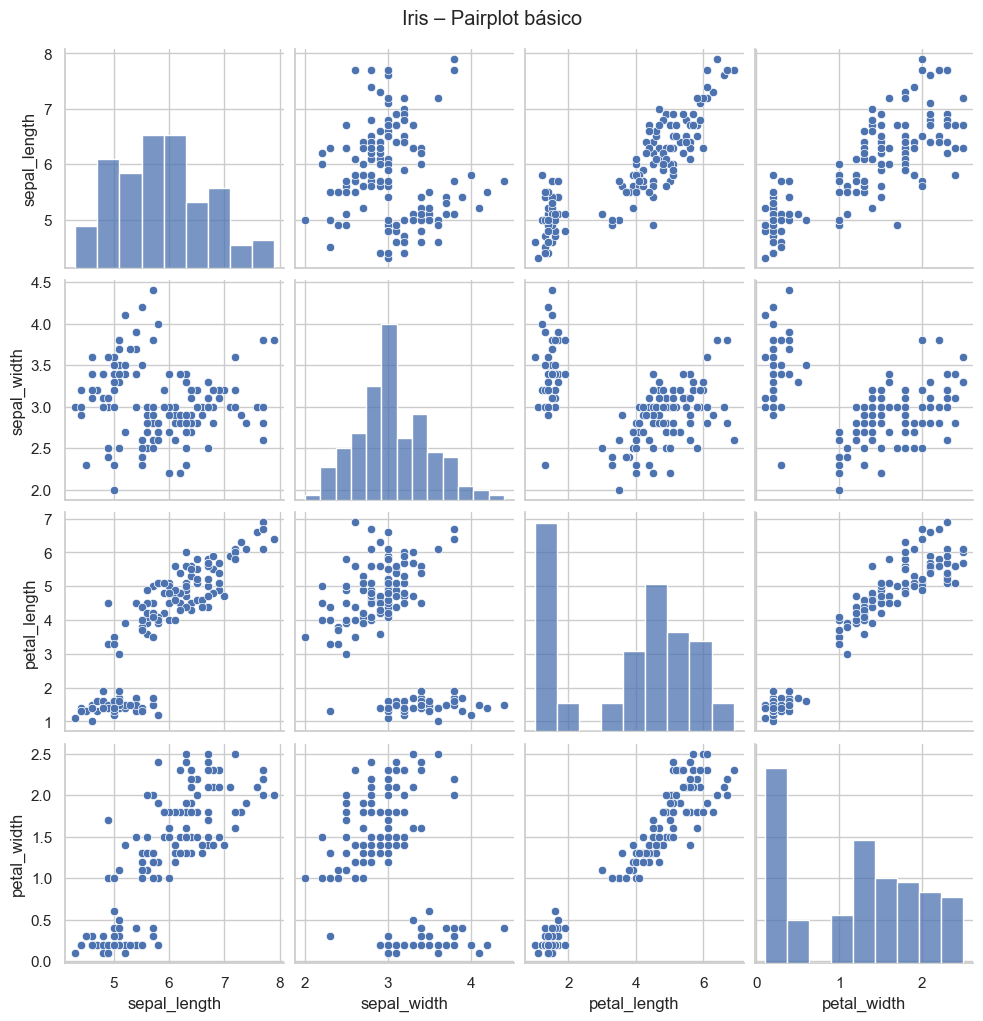

In [2]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="notebook")

iris = sns.load_dataset("iris")
g = sns.pairplot(data=iris)
g.fig.suptitle("Iris – Pairplot básico", y=1.02)
plt.show()

B) pairplot con hue y diagonal KDE
hue colorea por categoría (p. ej., especie).

diag_kind="kde" usa densidades suavizadas en la diagonal.

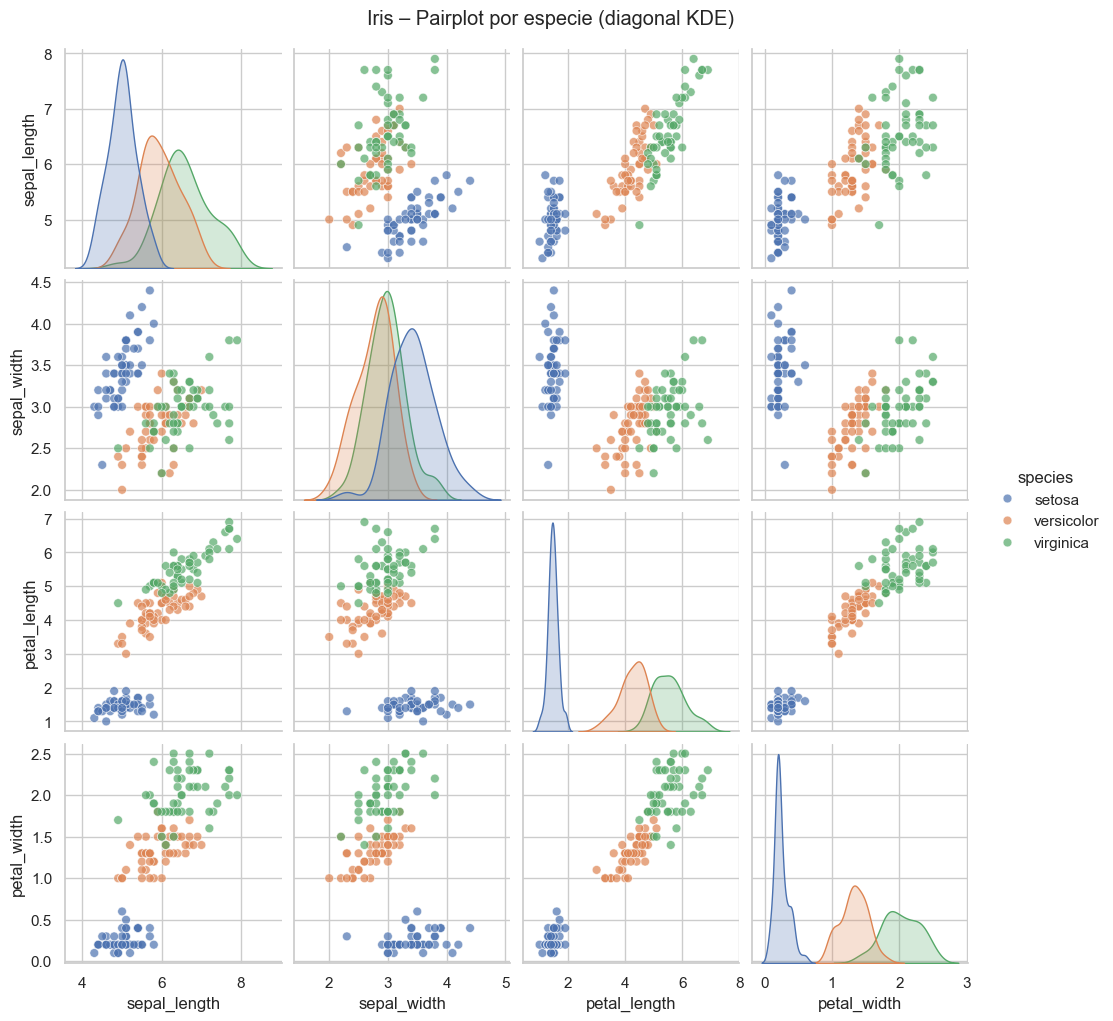

In [3]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="notebook")

iris = sns.load_dataset("iris")

g = sns.pairplot(
    data=iris,
    hue="species",
    diag_kind="kde",        # "hist" (default) o "kde"
    corner=False,           # True mostraría solo triángulo inferior
    plot_kws={"alpha": 0.7, "s": 40}  # kwargs para los scatter de la grilla
)
g.fig.suptitle("Iris – Pairplot por especie (diagonal KDE)", y=1.02)
plt.show()

C) pairplot solo con columnas seleccionadas + corner=True

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="notebook")

iris = sns.load_dataset("iris")
cols = ["sepal_length", "sepal_width", "petal_length", "petal_width"]

g = sns.pairplot(
    data=iris[cols],
    corner=True,        # muestra solo triángulo inferior
    diag_kind="hist"
)
g.fig.suptitle("Iris – Pairplot (solo columnas seleccionadas, corner=True)", y=1.02)
plt.show()

Tips (pairplot)
Si hay muchas columnas, el gráfico puede ser pesado; seleccioná variables clave.
corner=True mejora la legibilidad.
Ajustá plot_kws para controlar opacidad/tamaño de puntos.

6.2 jointplot: relación entre dos variables con distribuciones marginales
jointplot dibuja un gráfico central (relación X–Y) y, en los márgenes, las distribuciones de X y Y. Soporta varios kind: "scatter", "kde", "hist", "hex", "reg".

A) jointplot con dispersión + histogramas marginales

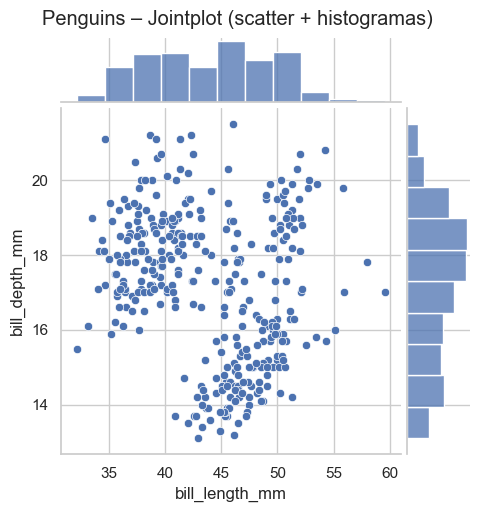

In [1]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="notebook")

penguins = sns.load_dataset("penguins").dropna(subset=["bill_length_mm", "bill_depth_mm"])

g = sns.jointplot(
    data=penguins,
    x="bill_length_mm",
    y="bill_depth_mm",
    kind="scatter",       # "scatter" por defecto
    height=5,             # tamaño de la figura
    space=0.1             # espacio entre centro y márgenes
)
g.fig.suptitle("Penguins – Jointplot (scatter + histogramas)", y=1.02)
plt.show()

B) jointplot con KDE 2D + KDE marginal (suavizado)

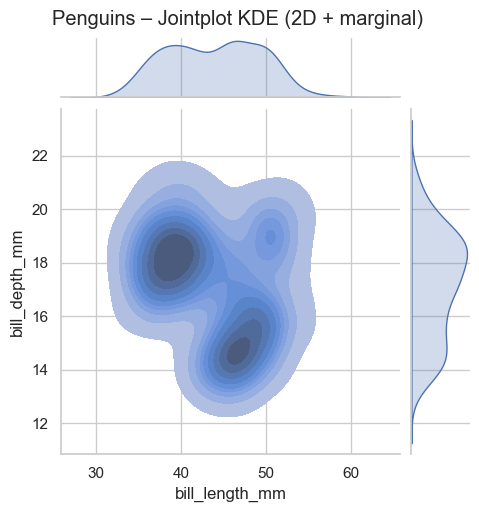

In [2]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="notebook")

penguins = sns.load_dataset("penguins").dropna(subset=["bill_length_mm", "bill_depth_mm"])

g = sns.jointplot(
    data=penguins,
    x="bill_length_mm",
    y="bill_depth_mm",
    kind="kde",          # densidad 2D en el centro + KDE marginal
    fill=True,           # relleno en KDE
    thresh=0.05,         # umbral de isolíneas
    height=5
)
g.fig.suptitle("Penguins – Jointplot KDE (2D + marginal)", y=1.02)
plt.show()

C) jointplot con hexbin (datos densos) o regresión (kind="reg")

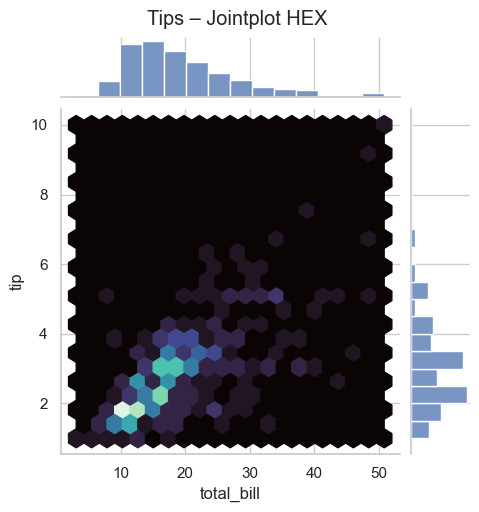

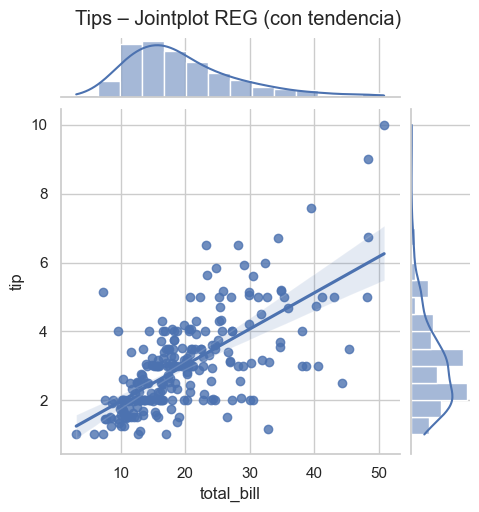

In [3]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="notebook")

tips = sns.load_dataset("tips")

# Hexbin (ideal para datos densos/solapados)
g1 = sns.jointplot(
    data=tips,
    x="total_bill", y="tip",
    kind="hex",
    height=5, gridsize=20,  # hexágonos
    cmap="mako"
)
g1.fig.suptitle("Tips – Jointplot HEX", y=1.02)

# Regresión simple (línea + bandas)
g2 = sns.jointplot(
    data=tips,
    x="total_bill", y="tip",
    kind="reg",           # scatter + recta + bandas
    height=5
)
g2.fig.suptitle("Tips – Jointplot REG (con tendencia)", y=1.02)

plt.show()

Tips (jointplot)
Elegí kind según el volumen y la distribución:
pocos puntos → scatter / reg
muchos puntos → hex
“forma” continua → kde
Ajustá height y space para mejorar la lectura.

6.3 lmplot: regresión lineal con intervalos de confianza
lmplot es una función de nivel figura (como relplot/catplot) que facilita:

Ajustar regresiones lineales (simples) por subgrupos con facetas.
Mostrar intervalos de confianza automáticos.
Dividir por hue, o por columnas/filas (col, row).
A) Regresión simple con bandas de confianza

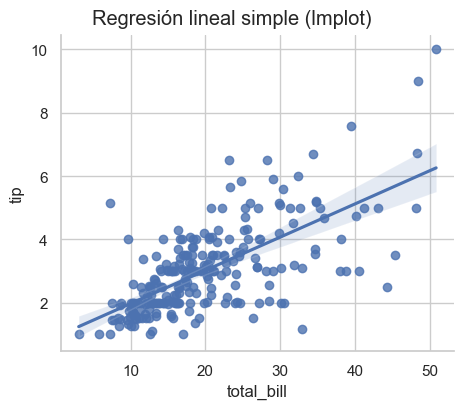

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="notebook")

tips = sns.load_dataset("tips")

g = sns.lmplot(
    data=tips,
    x="total_bill", y="tip",
    height=4, aspect=1.2,      # tamaño (figura de alto nivel)
    ci=95                      # nivel de confianza; None para ocultar
)
g.fig.suptitle("Regresión lineal simple (lmplot)", y=1.02)
plt.show()